Dataset: (41, 5)


,Section,Metric,Freetrade,Trading 212,Assessment / Notes
0,Executive conclusion,Overall positioning,Long-term investing platform with broad wrappe...,"Low-cost, broad exchange-traded investing plat...",Trading 212 generally suits frequent overseas ...
1,Ownership,Publicly listed?,No; wholly owned by IG Group Holdings plc,No; privately held group,Neither is a standalone publicly traded company
2,Ownership,Public-market exposure,Available indirectly through IG Group shares,No direct public-market exposure,Buying IG shares is not the same as buying Fre...
3,Ownership,Founders / control,Owned by IG Group after acquisition,Controlled by founders Borislav Nedialkov and ...,Private ownership limits direct investor acces...
4,Financials,Latest reported revenue,Approximately £31.0m for 2025 in available rep...,Approximately £345.8m group revenue for 2025,Not fully like-for-like; group structures differ


Text column: Assessment / Notes
Silhouette score: 0.026
Cluster 0: october, investment, support, availability, tariff, check, fx, published, published october, accessed october
Cluster 1: freetrade, advantage, freetrade advantage, trading advantage, trading, buying, shares, investing, advantage family, family
Cluster 2: trading, generally, trading generally, broader, stronger, reported, generally broader, profitability, trading reported, reported stronger
Cluster 3: available, available platforms, platforms, costs, compare pension, pension, pension costs, available investments, costs available, investments


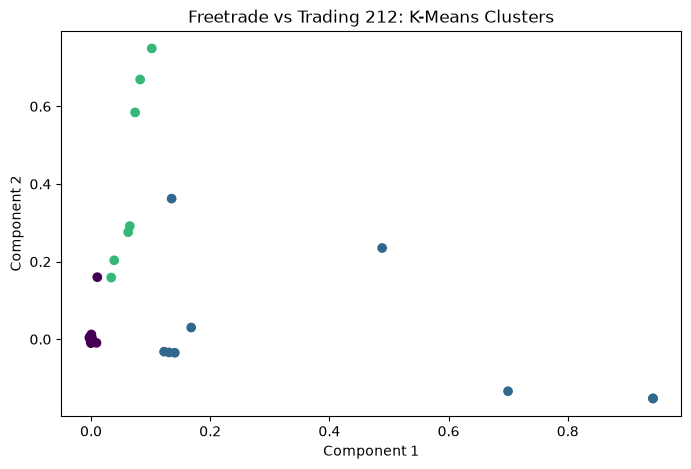

,reviews,average_sentiment
cluster,,
0,23,0.018
1,9,0.004
2,7,0.036
3,2,0.400


sentiment_label,Negative,Neutral,Positive
cluster,,,
0,1,20,2
1,0,9,0
2,0,4,3
3,0,0,2


Analysis complete. Results exported.


In [1]:
# Freetrade vs Trading 212: NLP + K-Means

# Install if needed:
# !pip install pandas numpy matplotlib scikit-learn textblob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from textblob import TextBlob

# 1. Load dataset
df = pd.read_csv("Freetrade_vs_Trading_212_Report.csv")
print("Dataset:", df.shape)
display(df.head())

# 2. Automatically select text column
cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
if not cols:
    raise ValueError("Dataset has no text columns.")

text_col = max(cols, key=lambda c: df[c].fillna("").astype(str).str.len().mean())
print("Text column:", text_col)

df = df.dropna(subset=[text_col]).copy()
df["clean_text"] = df[text_col].astype(str).str.lower()
df["clean_text"] = df["clean_text"].apply(
    lambda x: re.sub(r"http\S+|[^a-z\s]", " ", x)
)
df = df[df["clean_text"].str.strip().ne("")].copy()

# 3. NLP: TF-IDF
vectorizer = TfidfVectorizer(
    stop_words="english", max_features=3000, ngram_range=(1, 2)
)
X = vectorizer.fit_transform(df["clean_text"])

# 4. K-Means clustering
k = min(4, X.shape[0])
if k < 2:
    raise ValueError("At least two non-empty text records are required.")

model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["cluster"] = model.fit_predict(X)

if X.shape[0] > k:
    print("Silhouette score:", round(silhouette_score(X, df["cluster"]), 3))

# 5. Display key words per cluster
terms = vectorizer.get_feature_names_out()
for i, centre in enumerate(model.cluster_centers_):
    top = centre.argsort()[-10:][::-1]
    print(f"Cluster {i}:", ", ".join(terms[top]))

# 6. Sentiment analysis
df["sentiment"] = df["clean_text"].apply(
    lambda x: TextBlob(x).sentiment.polarity
)
df["sentiment_label"] = df["sentiment"].apply(
    lambda x: "Positive" if x > 0.05 else
              "Negative" if x < -0.05 else "Neutral"
)

# 7. Visualise clusters
if X.shape[0] >= 2:
    coords = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
    plt.figure(figsize=(8, 5))
    plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="viridis")
    plt.title("Freetrade vs Trading 212: K-Means Clusters")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.show()

# 8. Summarise results
display(df.groupby("cluster").agg(
    reviews=("clean_text", "count"),
    average_sentiment=("sentiment", "mean")
).round(3))

display(pd.crosstab(df["cluster"], df["sentiment_label"]))

# 9. Export results
df.to_csv("Freetrade_vs_Trading_212_NLP_KMeans_Results.csv", index=False)
print("Analysis complete. Results exported.")